# 06 · Oil scenarios and the forecaster tie-in

Maps a WTI % move to each segment's expected move using weekly oil betas with HAC bands. **This is sensitivity analysis, not a trading signal.**

In [1]:
import sys, json
sys.path.insert(0, "..")
import pandas as pd
pd.set_option("display.float_format", "{:,.3f}".format)
from IPython.display import Image, Markdown, display

In [2]:
from src.scenarios import oil, forecaster
res = oil.compute()
pd.DataFrame(res['weekly_betas']).T

,alpha,beta,se_hac,resid_sd,r2,n_weeks
majors,0.001,0.336,0.085,0.032,0.314,608.000
upstream,0.001,0.551,0.113,0.047,0.368,608.000
midstream,0.001,0.306,0.088,0.039,0.207,608.000
refiners,0.003,0.308,0.092,0.045,0.167,608.000
services,0.000,0.409,0.095,0.045,0.261,608.000


In [3]:
pd.DataFrame(oil.scenario(-10, res['weekly_betas'])).T

,expected_pct,param_band_pct,prediction_band_pct
majors,-3.364,"[-5.038111451007797, -1.6905671705912673]","[-9.933002847748371, 3.204324226149307]"
upstream,-5.514,"[-7.730345724694898, -3.2970196982802182]","[-14.996040600940997, 3.9686751779658787]"
midstream,-3.058,"[-4.778524312301056, -1.3377735625224703]","[-10.881178696356056, 4.76488082153253]"
refiners,-3.083,"[-4.885381389182775, -1.2815052307643238]","[-12.06295565416803, 5.896069034220932]"
services,-4.091,"[-5.957277773215827, -2.2240449463684224]","[-13.073818944169602, 4.8924962245853525]"


## Commodity-forecaster input
The forecaster publishes rolling one-step **backtest** forecasts in `results/leaderboard.json`. A dated copy is vendored in `data/vendor/`. Its last step has already been realized, so it is shown as a preset next to the slider, not as a forward view.

In [4]:
res['forecaster_input']

{'model': 'ARIMA(1,1,1)',
 'origin_week': '2026-09-20',
 'target_week': '2026-09-27',
 'origin_price': 100.3,
 'forecast_price': 100.2342,
 'implied_move_pct': -0.0656031904287091,
 'realized_price': 92.41,
 'realized_move_pct': -7.8664007976071755,
 'status': 'backtest step, already realized; not a forward forecast',
 'source_commit': '78b63d244934b882324e43216bc99bb27eee5176',
 'vendored_on': '2026-10-22'}

In [5]:
pd.DataFrame(res['forecaster_scenario']).T

,expected_pct,param_band_pct,prediction_band_pct
majors,-0.022,"[-0.03305161849215244, -0.011090660002482286]","[-6.373917174474268, 6.329774895979632]"
upstream,-0.036,"[-0.05071353426569167, -0.021629501111348214]","[-9.255809672182682, 9.183466636805642]"
midstream,-0.020,"[-0.031348644042810236, -0.008776221377265421]","[-7.65159114964276, 7.611466284222683]"
refiners,-0.020,"[-0.0320496605591429, -0.008407083168921874]","[-8.817091496927604, 8.776634753199538]"
services,-0.027,"[-0.0390816428192994, -0.01459044441386157]","[-8.813929607793286, 8.760257520560124]"


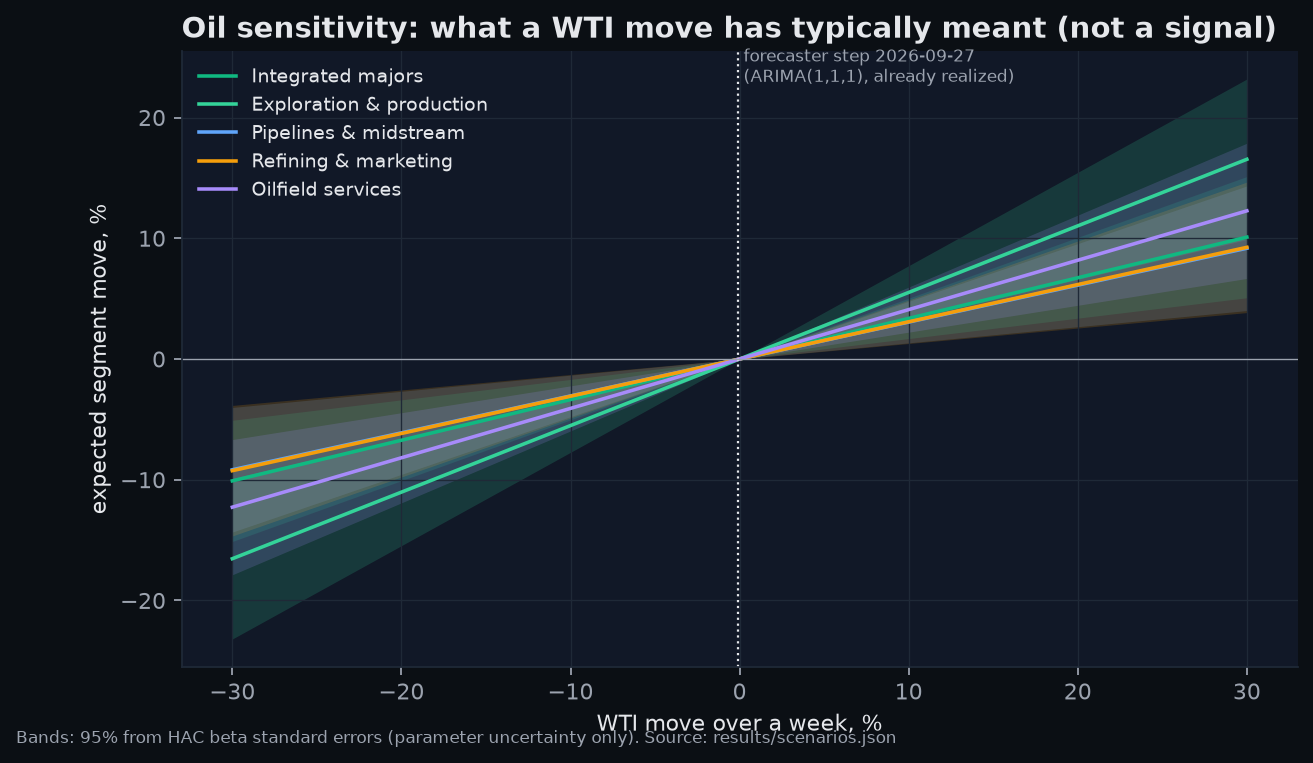

In [6]:
Image('../docs/img/scenario_fan.png')